### Questão 1
O objetivo da função Black-Scholes é precificar opções europeias. As variáveis são: S é o preço spot da ação, K é o strike da opção, T é o tempo até o vencimento, r é a taxa livre de risco e sigma é a volatilidade (desvio padrão) da ação.

In [50]:
import numpy as np
import pandas as pd
import sympy as sp

S, K, T, r, sigma, C, P = sp.symbols('S K T r sigma C P', positive=True)
d1_simbolo, d2_simbolo = sp.symbols('d1 d2')
N_funcao = sp.Function('N')

# Versão para CALCULAR (usada nas próximas questões)
def N(x):
    return (1 + sp.erf(x / sp.sqrt(2))) / 2

d1 = (sp.ln(S / K) + (r + sigma ** 2 / 2) * T) / (sigma * sp.sqrt(T))
d2 = d1 - sigma * sp.sqrt(T)
call = S * N(d1) - K * sp.exp(-r * T) * N(d2)
put = K * sp.exp(-r * T) * N(-d2) - S * N(-d1)

# Versão para MOSTRAR (só para exibir bonito)
formula_call = sp.Eq(C, S * N_funcao(d1_simbolo) - K * sp.exp(-r * T) * N_funcao(d2_simbolo))
formula_put = sp.Eq(P, K * sp.exp(-r * T) * N_funcao(-d2_simbolo) - S * N_funcao(-d1_simbolo))
formula_d1 = sp.Eq(d1_simbolo, d1)
formula_d2 = sp.Eq(d2_simbolo, d1_simbolo - sigma * sp.sqrt(T))

sp.pprint(formula_call)
print()
print("=" * 60)
sp.pprint(formula_put)
print()
print("=" * 60)
print()
sp.pprint(formula_d1)
print()
print("=" * 60)
sp.pprint(formula_d2)

               -T⋅r          
C = - K⋅N(d₂)⋅ℯ     + S⋅N(d₁)

              -T⋅r           
P = K⋅N(-d₂)⋅ℯ     - S⋅N(-d₁)


       ⎛     2⎞         
       ⎜    σ ⎟      ⎛S⎞
     T⋅⎜r + ──⎟ + log⎜─⎟
       ⎝    2 ⎠      ⎝K⎠
d₁ = ───────────────────
            √T⋅σ        

d₂ = -√T⋅σ + d₁


### Questão 2
A intuição é que, se precificadas de forma justa, comprar uma call e manter o dinheiro do strike em uma taxa livre de risco dá o mesmo payoff que comprar uma put e a ação com o preço presente, visto que se a ação sobre acima de K, você compra a ação por K no primeiro caso, e mantém ela no segundo, e se a ação cai abaixo de K, você não exerce a opção no primeiro prazo (tem K na taxa livre de risco), e exerce a opção de venda no segundo caso (ganhando K).

In [51]:
valores = {S: 200, K: 200, T: 1, r: 0.1375, sigma: 0.3}

preco_call = call.subs(valores).evalf()
preco_put = put.subs(valores).evalf()
esquerdo = preco_call + valores[K] * sp.exp(-valores[r] * valores[T])
direito = preco_put + valores[S]    

print(direito)
print(esquerdo)


211.750732991666
211.750732991666


### Questão 3
- Delta é a primeira derivada da fórmula da opção em relação ao preço, ou seja, representa a taxa de variação do preço da call quando o preço da ação muda.
- Gamma é a segunda derivada da fórmula da opção em relação ao preço, ou seja, representa a taxa de variação de delta quando o preço da ação muda.
- Theta é a derivada da fórmula da opção em relação a T, mostrando o quanto o preço da opção cai conforme o tempo avança (visto que há menos possibilidade da opção dar certo)
- Vega é a derivada da fórmula da opção em relação a sigma, representando a variação do preço da opção quando a volatilidade é alterada.

In [52]:
phi_funcao = sp.Function('phi')

def phi(x):
    return sp.exp(-x**2 / 2) / sp.sqrt(2 * sp.pi)

#Derivadas da função de preço do call em relação a S, T e sigma
delta_derivada = sp.diff(call, S)
gamma_derivada = sp.diff(call, S, 2)
theta_derivada = -sp.diff(call, T)
vega_derivada = sp.diff(call, sigma)

#Fórmulas das gregas
delta = N(d1)
gamma = phi(d1) / (S * sigma * sp.sqrt(T))
theta = -S * phi(d1) * sigma / (2 * sp.sqrt(T)) - r * K * sp.exp(-r * T) * N(d2)
vega = S * phi(d1) * sp.sqrt(T)

#Exibindo as fórmulas das gregas
delta_formula = sp.Eq(sp.Symbol('Delta'), N_funcao(d1_simbolo))
gamma_formula = sp.Eq(sp.Symbol('Gamma'), phi_funcao(d1_simbolo) / (S * sigma * sp.sqrt(T)))
theta_formula = sp.Eq(sp.Symbol('Theta'), -S * phi_funcao(d1_simbolo) * sigma / (2 * sp.sqrt(T)) - r * K * sp.exp(-r * T) * N_funcao(d2_simbolo))
vega_formula = sp.Eq(sp.Symbol('Vega'), S * phi_funcao(d1_simbolo) * sp.sqrt(T))

sp.pprint(delta_formula)
print()
print("=" * 60)
sp.pprint(gamma_formula)
print()
print("=" * 60)
sp.pprint(theta_formula)
print()
print("=" * 60)
sp.pprint(vega_formula)
print()
print("=" * 60)


Δ = N(d₁)

    φ(d₁) 
Γ = ──────
    S⋅√T⋅σ

                 -T⋅r   S⋅σ⋅φ(d₁)
Θ = - K⋅r⋅N(d₂)⋅ℯ     - ─────────
                          2⋅√T   

Vega = S⋅√T⋅φ(d₁)



### Questão 4


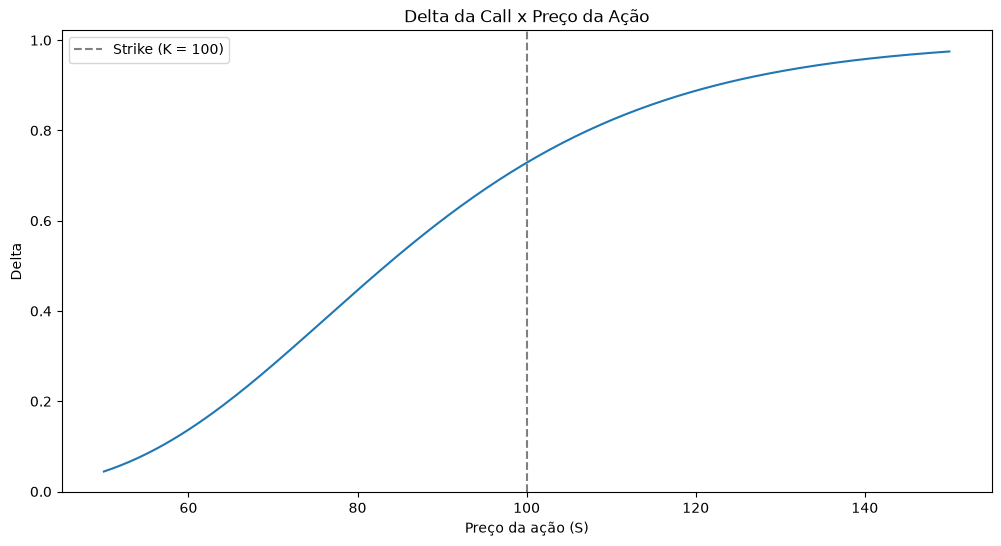

In [53]:
import matplotlib.pyplot as plt

numero_exemplo = {K: 100, T: 1, r: 0.1375, sigma: 0.3}
delta_func = sp.lambdify(S, delta.subs(numero_exemplo))

precos = np.linspace(50, 150, 200)

plt.figure(figsize=(12, 6))
plt.plot(precos, delta_func(precos))
plt.axvline(100, color='gray', linestyle='--', label='Strike (K = 100)')
plt.title('Delta da Call x Preço da Ação')
plt.xlabel('Preço da ação (S)')
plt.ylabel('Delta')
plt.legend()
plt.show()